<a href="https://colab.research.google.com/github/ManasDasri/NNDL/blob/main/notebooks/4_problem2_longformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4 · Problem 2 — does longer context help?

BERT at 512 tokens against Longformer at 4,096. Both train on chunks, because 70%
of contracts exceed 4,096 as well. What differs is how much context one window
holds: about 300 words against about 2,600.

**Needs a GPU with real memory.** Longformer at 4,096 tokens wants a small batch
and gradient checkpointing; budget a few hours on a T4.


## Setup

Clone the repository and install. The data layer needs nothing beyond the standard
library, so this is only for the model code.


In [1]:
# Safe to re-run in the same session: clones once, then pulls, and always works from
# $ROOT/NNDL. Re-running a plain `git clone` + `%cd NNDL` used to nest a second
# copy inside the first.
import os, sys
# Colab works in /content, Kaggle in /kaggle/working; everything else is the same.
ROOT = '/kaggle/working' if os.path.isdir('/kaggle/working') else '/content'
%cd $ROOT
!test -d NNDL || git clone -q https://github.com/ManasDasri/NNDL.git
%cd $ROOT/NNDL
!git pull -q
!pip install -q -e . 'matplotlib>=3.8'
# pip -e registers the package when Python starts, so this already-running kernel
# can't see it yet; the command-line tools can. Point the kernel at the source.
sys.path.insert(0, f'{ROOT}/NNDL/src')

import torch
if not torch.cuda.is_available():
    raise RuntimeError('No GPU, so training would take many hours. Colab: Runtime > Change runtime type > T4 GPU. '
                       'Kaggle: Settings > Accelerator > GPU T4 x2, and turn Internet on. Then run all.')
print('GPU:', torch.cuda.get_device_name(0))

/kaggle/working
/kaggle/working/NNDL
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for legal-risk-clause-classifier (pyproject.toml) ... done
GPU: Tesla T4


### Prepare the corpus

Extracts answer spans from `CUAD_v1.json` and assigns document-level splits.
Chunking happens at training time, because each model needs a different window.


In [2]:
!legal-risk-prepare --cuad_json data/CUAD_v1.json --out_dir data/processed


510 documents -> data/processed/documents.jsonl
splits {'train': 358, 'val': 76, 'test': 76} -> data/processed/splits.json
  Cap on Liability                   662 spans across  275 documents
  Non-Compete                        251 spans across  119 documents
  License Grant                      772 spans across  255 documents
  Audit Rights                       639 spans across  214 documents
  Termination for Convenience        245 spans across  183 documents
  Insurance                          554 spans across  166 documents


### Train Longformer

`[CLS]` is given global attention so the classification head reads a token that
attended to the whole window. Without it the head sees only a local neighbourhood
and the long context is wasted on the one position that matters.


**Rerun after the whitespace fix.** Longformer's tokenizer used to spend a token on
every run of layout spaces in these OCR'd contracts, which pushed 20% of windows past
4,096 tokens and cut their tails off. Text is now collapsed before tokenizing, so the
earlier Longformer result predates the fix. See `docs/weak-points.md`.

In [3]:
!legal-risk-train-transformer --model longformer --epochs 10 --patience 2 \
    --batch_size 1 --grad_accumulation 16 --lr 2e-5 \
    --gradient_checkpointing --output_dir outputs/longformer


allenai/longformer-base-4096  window=2600w overlap=400w max_length=4096t
{'train': 1380, 'val': 295, 'test': 326}
config.json: 100%|█████████████████████████████| 694/694 [00:00<00:00, 2.93MB/s]
vocab.json: 100%|████████████████████████████| 899k/899k [00:00<00:00, 55.8MB/s]
merges.txt: 100%|████████████████████████████| 456k/456k [00:00<00:00, 83.9MB/s]
tokenizer.json: 100%|██████████████████████| 1.36M/1.36M [00:00<00:00, 97.9MB/s]

pytorch_model.bin: downloading bytes: █████▊                |  159MB, 11.6MB/s  
pytorch_model.bin: downloading bytes: ███████▊              |  213MB, 18.2MB/s  
pytorch_model.bin: downloading bytes: ███████████           |  302MB, 23.3MB/s  
pytorch_model.bin: downloading bytes: ████████████▋         |  344MB, 28.0MB/s  
pytorch_model.bin: downloading bytes: ██████████████████████|  363MB, 33.2MB/s  
pytorch_model.bin: reconstructing file: 100%|██████|  597MB /  597MB, 55.3MB/s  
Loading weights: 100%|██████████████████████| 269/269 [00:00<00:00, 8339.87

### Compare against the 512-token model


In [4]:
# Compare whatever has finished; legal-risk-compare skips missing runs.
!legal-risk-evaluate --run_dir outputs/longformer --split test
!legal-risk-compare outputs/cnn outputs/bert outputs/legal_bert outputs/longformer


Loading weights: 100%|█████████████████████| 269/269 [00:00<00:00, 12347.66it/s]
[transformers] LongformerForSequenceClassification LOAD REPORT from: allenai/longformer-base-4096
Key                            | Status     | 
-------------------------------+------------+-
longformer.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight      | UNEXPECTED | 
lm_head.decoder.weight         | UNEXPECTED | 
lm_head.dense.bias             | UNEXPECTED | 
longformer.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias        | UNEXPECTED | 
lm_head.bias                   | UNEXPECTED | 
lm_head.dense.weight           | UNEXPECTED | 
classifier.dense.bias          | MISSING    | 
classifier.dense.weight        | MISSING    | 
classifier.out_proj.bias       | MISSING    | 
classifier.out_proj.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initial

In [5]:
print(open('docs/results.md').read())


# Model comparison

Generated by `legal-risk-compare` from the runs themselves, on the test split.
Every model saw identical chunks, identical document-level splits, the same
weighted loss and the same per-label threshold tuning, so the differences below
are differences between models.

## Chunk-level results

| Model | Context | Chunk words | macro F1 | macro AP | Best epoch |
| --- | ---: | ---: | ---: | ---: | ---: |
| allenai/longformer-base-4096 | 4096 | 2600 | 0.736 | 0.782 | 7 |

## Per-class F1

| Model | Cap on Liability | Non-Compete | License Grant | Audit Rights | Termination for Convenience | Insurance |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| longformer | 0.813 | 0.400 | 0.883 | 0.855 | 0.536 | 0.927 |

## Document-level results

Chunk predictions pooled to a contract-level decision. This is the number that
matters for the tool as it would be used: does this contract contain the clause?

| Model | Pooling | macro F1 | macro AP |
| --- | --- | ---: | ---: |
| l

### Cost, which belongs in the comparison

Longformer is larger and much slower. If it wins by a small margin, the honest
reporting includes what that margin cost.


In [6]:
import json, pathlib

for name in ('bert', 'legal_bert', 'longformer'):
    path = pathlib.Path('outputs') / name / 'metrics.json'
    if not path.exists():
        print(f'{name:12s} not trained yet')
        continue
    m = json.load(open(path))
    print(f"{name:12s} {m['parameters']:>12,} params  "
          f"window {m['chunking']['window']:>5} words  "
          f"train windows {m['chunks']['train']:>6,}  "
          f"macro F1 {m['test_at_tuned_thresholds']['macro_f1']:.3f}")


bert         not trained yet
legal_bert   not trained yet
longformer    148,664,070 params  window  2600 words  train windows  1,380  macro F1 0.736


### A null result is a result

Most of these clauses are locally signalled — *"shall maintain insurance"* is
recognisable from its own sentence. If Longformer does not win, that is a finding
about the task: clause detection in contracts is a local problem, and the expensive
long-context machinery is not what it needs. Say that plainly rather than treating
it as a failed experiment.


### Classification reports and plots

For every evaluated run: its classification report, a confusion matrix per label at
window and contract level, and precision, recall, F1 and accuracy by label. The last
chart compares every run at contract level.

longformer · test split

Window level (326 windows of 2600 words, validation-tuned thresholds)

                             precision    recall  f1-score   support

           Cap on Liability      0.820     0.806     0.813        62
                Non-Compete      0.315     0.548     0.400        31
              License Grant      0.865     0.901     0.883        71
               Audit Rights      0.794     0.926     0.855        54
Termination for Convenience      0.406     0.788     0.536        33
                  Insurance      0.950     0.905     0.927        42

                  micro avg      0.688     0.836     0.755       293
                  macro avg      0.692     0.812     0.736       293
               weighted avg      0.745     0.836     0.779       293
                samples avg      0.446     0.489     0.449       293
Samples avg scores each window over its own labels, so the many windows with no
clause count as zero here. Read the per-class rows and the macr

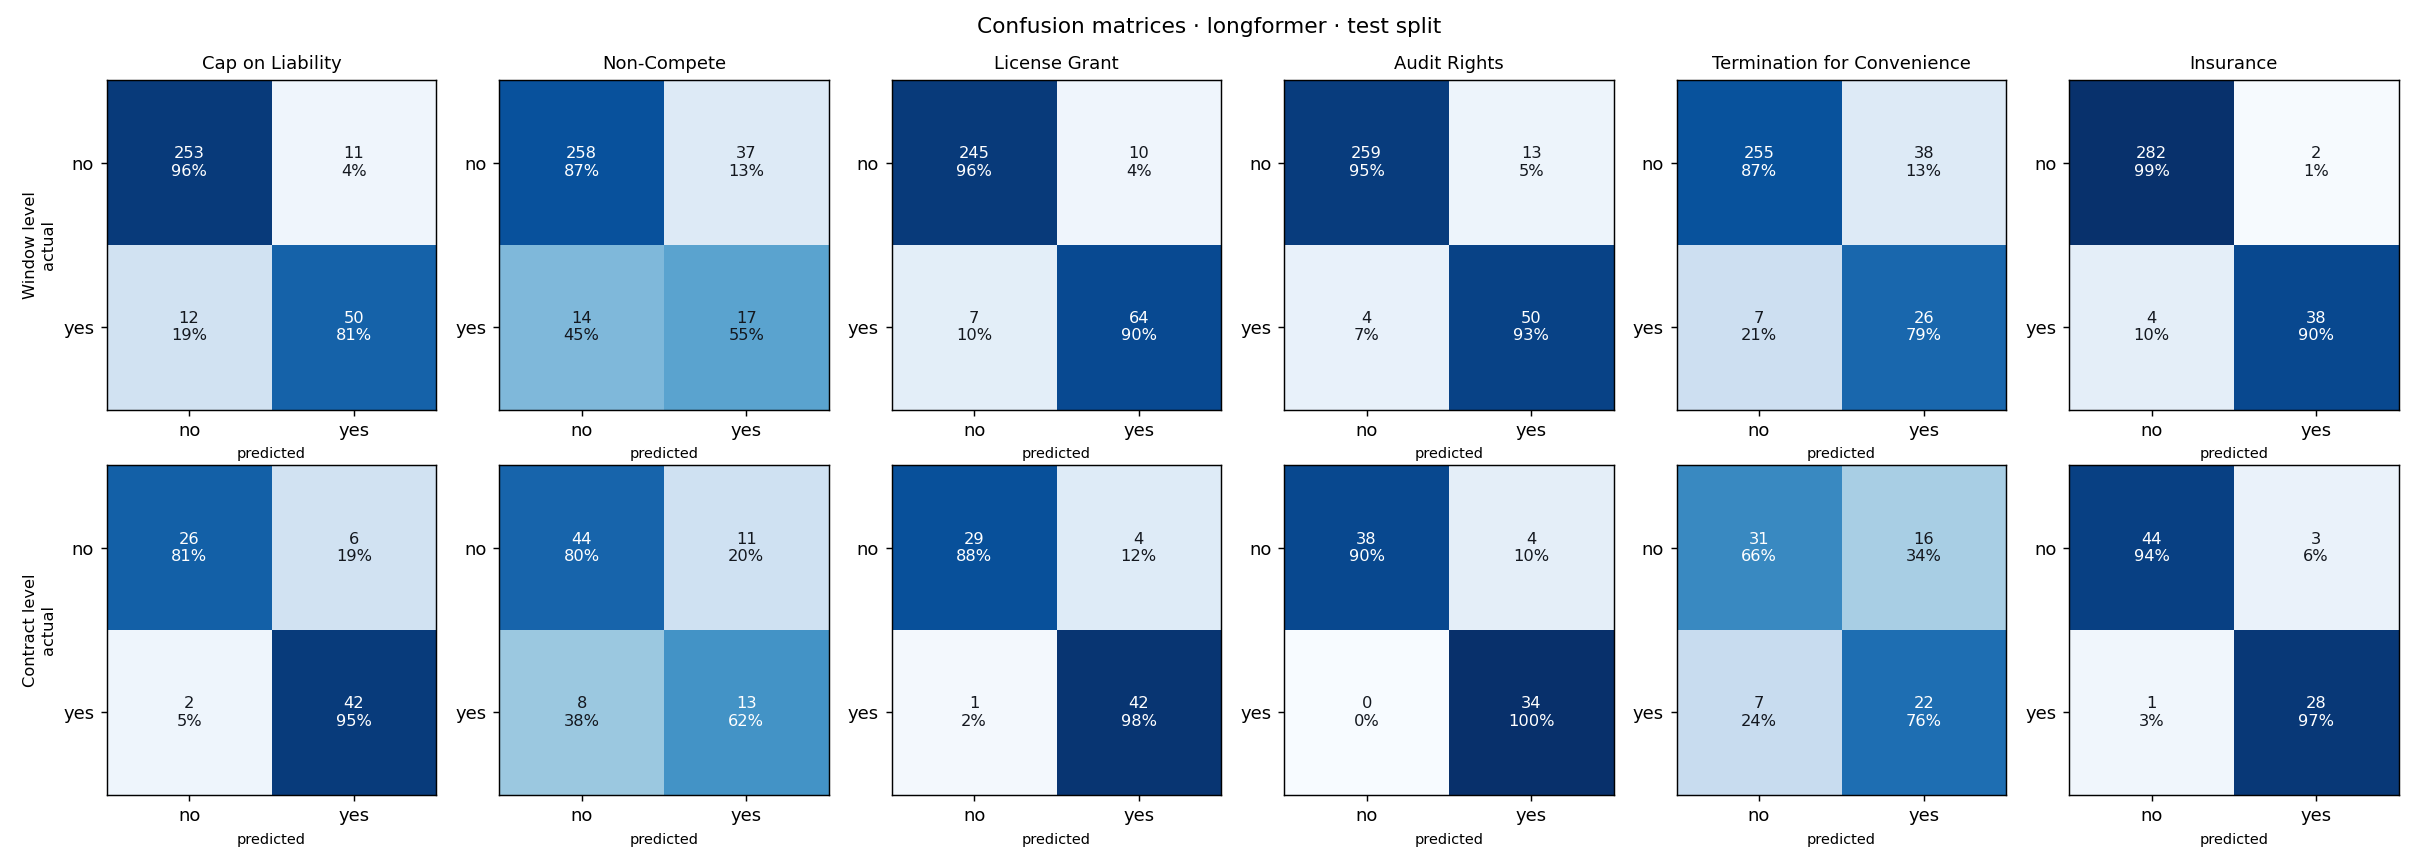

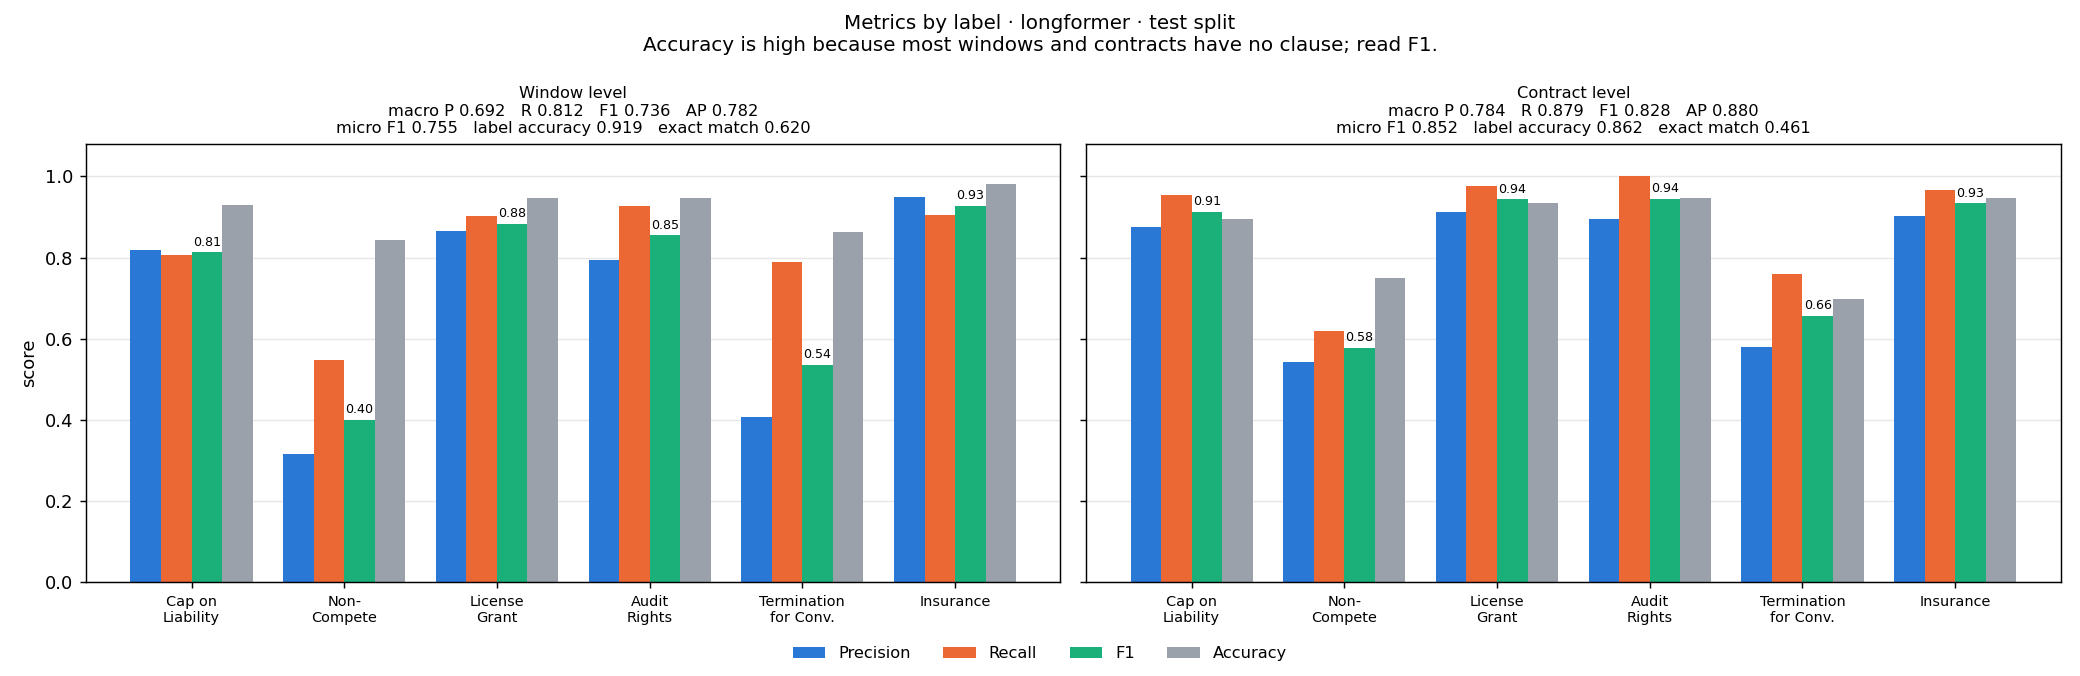

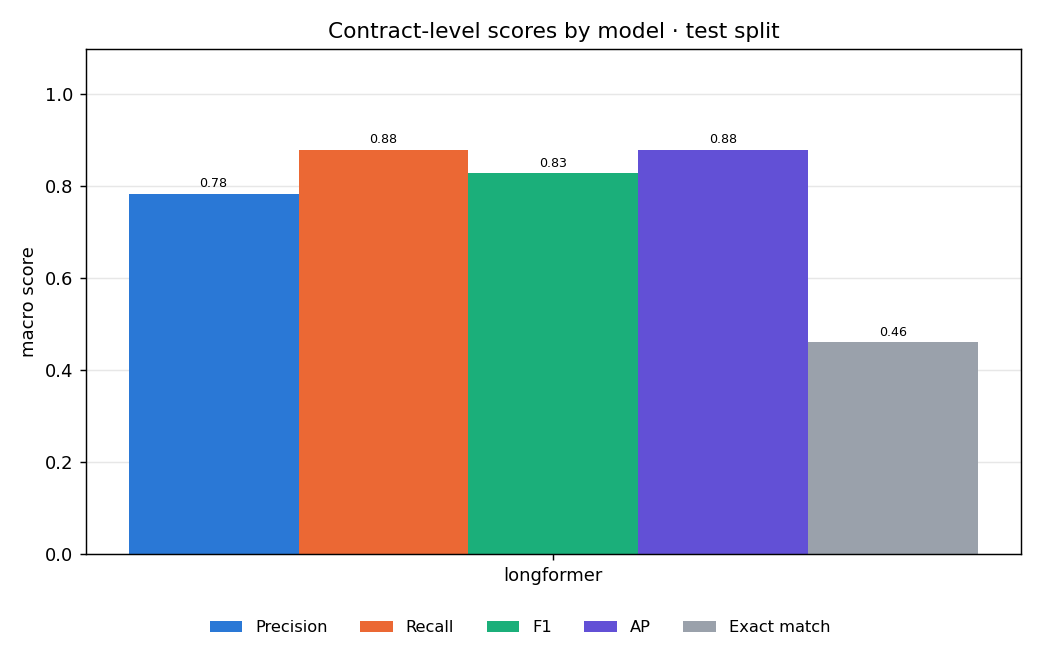

In [7]:
# Plots for every evaluated run: confusion matrices, then precision, recall, F1 and
# accuracy by label, then all runs side by side. Saved as PNGs in each run folder.
import pathlib
from IPython.display import Image, display
from legal_risk_classifier.plots import plot_run, plot_comparison

runs = sorted(path.parent for path in pathlib.Path('outputs').glob('*/evaluation_test.json'))
for run in runs:
    print('=' * 78)
    print((run / 'classification_report_test.txt').read_text())
    for png in plot_run(run, show=False):
        display(Image(str(png)))
display(Image(str(plot_comparison(runs, show=False))))